# Credit default scoring

Predict next-month default (1), not a general credit score. The source contains Taiwanese clients from 2005. Financial history features and three row-wise engineered features are used. ID and direct demographics (sex, education, marital status, age) are excluded. This does not remove proxy bias.

The initial 30,000 rows lose 732 identical retained-feature/label rows; another 170 rows with contradictory labels for an identical retained financial profile are excluded. The final 29,098 rows have unique retained feature profiles. This cleaning choice changes the population and may remove legitimate clients with similar histories; it is an educational leakage-control choice, not a production data-cleaning recommendation. No missing cells are expected. The preprocessing pipeline still includes a training-fitted median imputer.

Five-fold stratified cross-validation on the 80% training partition selects between logistic regression and a random forest by ROC-AUC. Only the selected model and a majority baseline are evaluated on the 20% test partition. The 0.5 classification threshold is not tuned on the test set. Accuracy alone is misleading for the imbalanced outcome. The model misses many defaults, so ROC-AUC and recall must be read together. This is not suitable for lending decisions, and no fairness, calibration, legal or out-of-time validation is claimed.

Prepared with AI assistance for review. This notebook has been run, but no internship submission is claimed.

## Reproducible implementation

The source below uses seed 42, a training-only validation process and a held-out test set. Install requirements.txt before running. Run all cells from this project folder.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
 roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
 RocCurveDisplay, mean_absolute_error, mean_squared_error, r2_score)
BASE=Path.cwd()
OUT=BASE/"results"
OUT.mkdir(exist_ok=True)
SEED=42

def classify(X, y, names, title):
    assert len(X)==len(y) and not pd.Series(y).isna().any()
    # Exclude contradictory labels for identical feature profiles, then collapse duplicates.
    frame=X.reset_index(drop=True).copy()
    frame["__target"]=np.asarray(y)
    keys=list(X.columns)
    conflicts=frame.groupby(keys,dropna=False)["__target"].transform("nunique")>1
    raw_rows=len(frame)
    frame=frame.loc[~conflicts].drop_duplicates(subset=keys).reset_index(drop=True)
    y=frame.pop("__target").to_numpy()
    X=frame
    quality={"input_rows":raw_rows,"conflicting_profile_rows_removed":int(conflicts.sum()),"duplicate_rows_removed":raw_rows-int(conflicts.sum())-len(frame),"analysis_rows":len(frame)}
    (OUT/"data_quality.json").write_text(json.dumps(quality,indent=2))
    indices=np.arange(len(y))
    train_idx,test_idx=train_test_split(indices,test_size=.2,stratify=y,random_state=SEED)
    assert not set(train_idx)&set(test_idx)
    Xtrain,Xtest=X.iloc[train_idx],X.iloc[test_idx]
    ytrain,ytest=np.asarray(y)[train_idx],np.asarray(y)[test_idx]
    models={"baseline":DummyClassifier(strategy="most_frequent"),
            "logistic":make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),LogisticRegression(max_iter=3000,random_state=SEED)),
            "forest":make_pipeline(SimpleImputer(strategy="median"),RandomForestClassifier(n_estimators=120,min_samples_leaf=4,class_weight="balanced",random_state=SEED,n_jobs=2))}
    multiclass=len(names)>2
    scoring="f1_macro" if multiclass else "roc_auc"
    cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
    cvresults={}
    for name,model in models.items():
        scores=cross_val_score(model,Xtrain,ytrain,cv=cv,scoring=scoring,n_jobs=1)
        cvresults[name]={"mean":float(scores.mean()),"std":float(scores.std())}
    winner=max((k for k in models if k!="baseline"),key=lambda k:cvresults[k]["mean"])
    rows=[]
    for name in ["baseline",winner]:
        model=models[name].fit(Xtrain,ytrain)
        pred=model.predict(Xtest)
        p=model.predict_proba(Xtest)
        avg="macro" if multiclass else "binary"
        row={"model":name,"accuracy":accuracy_score(ytest,pred),"precision":precision_score(ytest,pred,average=avg,zero_division=0),"recall":recall_score(ytest,pred,average=avg,zero_division=0),"f1":f1_score(ytest,pred,average=avg,zero_division=0)}
        if not multiclass:
            row.update(roc_auc=roc_auc_score(ytest,p[:,1]),average_precision=average_precision_score(ytest,p[:,1]))
        rows.append(row)
        if name==winner:
            fig,ax=plt.subplots(figsize=(6,5))
            ConfusionMatrixDisplay.from_predictions(ytest,pred,display_labels=names,ax=ax,colorbar=False,cmap="Blues")
            ax.set_title(title+" | held-out test")
            fig.tight_layout(); fig.savefig(OUT/"confusion_matrix.png",dpi=160);plt.close(fig)
            if not multiclass:
                fig,ax=plt.subplots(figsize=(6,5)); RocCurveDisplay.from_predictions(ytest,p[:,1],ax=ax)
                ax.plot([0,1],[0,1],"--",color="gray");ax.set_title(title+" | ROC");ax.legend([f"ROC-AUC = {roc_auc_score(ytest,p[:,1]):.4f}"],loc="lower right")
                fig.tight_layout();fig.savefig(OUT/"roc_curve.png",dpi=160);plt.close(fig)
            pd.DataFrame({"source_row":test_idx,"actual":ytest,"predicted":pred}).to_csv(OUT/"test_predictions.csv",index=False)
    result={"rows":len(y),"train_rows":len(train_idx),"test_rows":len(test_idx),"seed":SEED,"positive_class":None if multiclass else names[1],"cv_metric":scoring,"cv_train_only":cvresults,"selected_model":winner,"held_out":rows,"class_counts":pd.Series(y).value_counts().sort_index().to_dict()}
    (OUT/"metrics.json").write_text(json.dumps(result,indent=2))
    pd.DataFrame(rows).to_csv(OUT/"metrics.csv",index=False)
    print(json.dumps(result,indent=2))
    return result

import hashlib, urllib.request, zipfile, io
DATA=BASE/"data"
DATA.mkdir(exist_ok=True)
file=DATA/"credit.xls"
url="https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
if not file.exists():
    req=urllib.request.Request(url,headers={"User-Agent":"Educational reproducibility project"})
    archive=zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(req,timeout=90).read()))
    entry=next(n for n in archive.namelist() if n.endswith(".xls"))
    file.write_bytes(archive.read(entry))
df=pd.read_excel(file,header=1)
assert len(df)==30000 and "default payment next month" in df.columns
# Remove identical financial profiles before the split to reduce profile leakage.
# Direct demographics are excluded, but financial proxies can still carry bias.
df=df.drop(columns=["ID","SEX","EDUCATION","MARRIAGE","AGE"]).drop_duplicates().reset_index(drop=True)
y=df.pop("default payment next month").astype(int)
X=df.copy()
bills=X[[f"BILL_AMT{i}" for i in range(1,7)]]
payments=X[[f"PAY_AMT{i}" for i in range(1,7)]]
# Row-wise only: no statistics from held-out clients.
X["mean_bill_to_limit"]=bills.mean(axis=1)/X["LIMIT_BAL"].clip(lower=1)
X["total_recent_payments"]=payments.sum(axis=1)
X["months_delayed"]=(X[["PAY_0","PAY_2","PAY_3","PAY_4","PAY_5","PAY_6"]]>0).sum(axis=1)
result=classify(X,y,["No default","Default"],"Credit default")
(OUT/"data_provenance.json").write_text(json.dumps({"source":url,"sha256":hashlib.sha256(file.read_bytes()).hexdigest(),"raw_rows":30000,"deduplicated_feature_label_rows_before_conflict_filter":len(df),"removed_duplicate_profiles":30000-len(df)},indent=2))


{
  "rows": 29098,
  "train_rows": 23278,
  "test_rows": 5820,
  "seed": 42,
  "positive_class": "Default",
  "cv_metric": "roc_auc",
  "cv_train_only": {
    "baseline": {
      "mean": 0.5,
      "std": 0.0
    },
    "logistic": {
      "mean": 0.7551868255075866,
      "std": 0.008714858735090881
    },
    "forest": {
      "mean": 0.7713147419572226,
      "std": 0.004047778909886195
    }
  },
  "selected_model": "forest",
  "held_out": [
    {
      "model": "baseline",
      "accuracy": 0.784192439862543,
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "roc_auc": 0.5,
      "average_precision": 0.21580756013745706
    },
    {
      "model": "forest",
      "accuracy": 0.8116838487972509,
      "precision": 0.5785854616895875,
      "recall": 0.46894904458598724,
      "f1": 0.5180299032541776,
      "roc_auc": 0.765047666032143,
      "average_precision": 0.5421218768389098
    }
  ],
  "class_counts": {
    "0": 22820,
    "1": 6278
  }
}


303

## Read the result

| Model | accuracy | precision | recall | f1 | roc_auc | average_precision |
|---|---:|---:|---:|---:|---:|---:|
| baseline | 0.7842 | 0.0000 | 0.0000 | 0.0000 | 0.5000 | 0.2158 |
| forest | 0.8117 | 0.5786 | 0.4689 | 0.5180 | 0.7650 | 0.5421 |


Do not confuse a good benchmark score with real-world validation. Compare with the baseline and read the limits above.

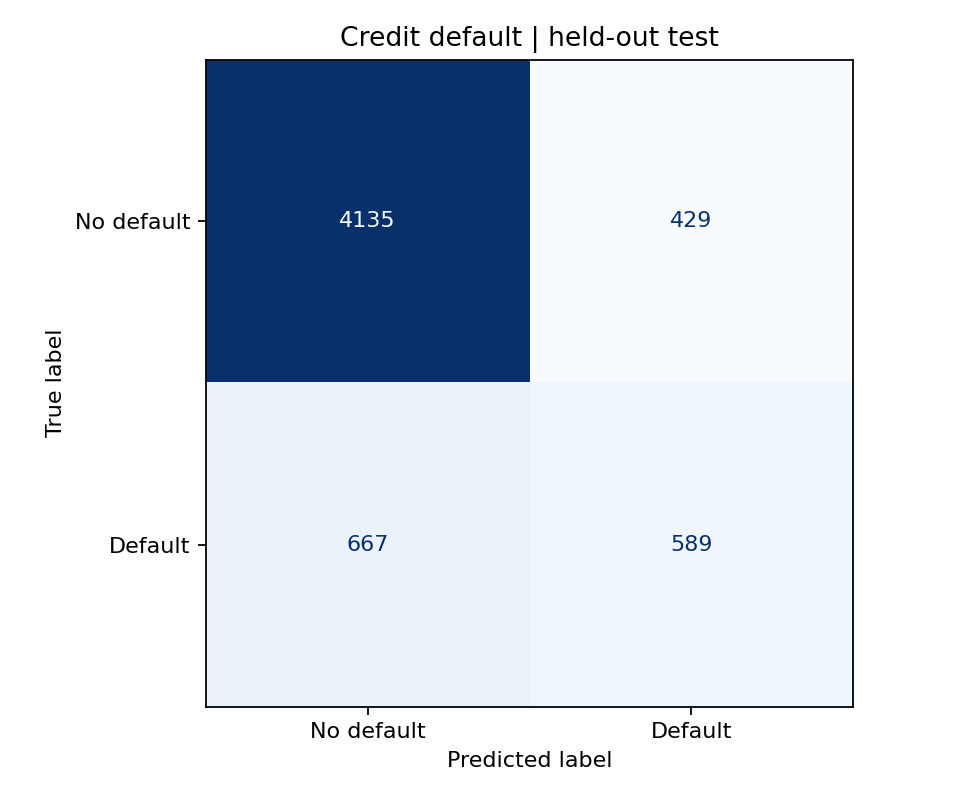

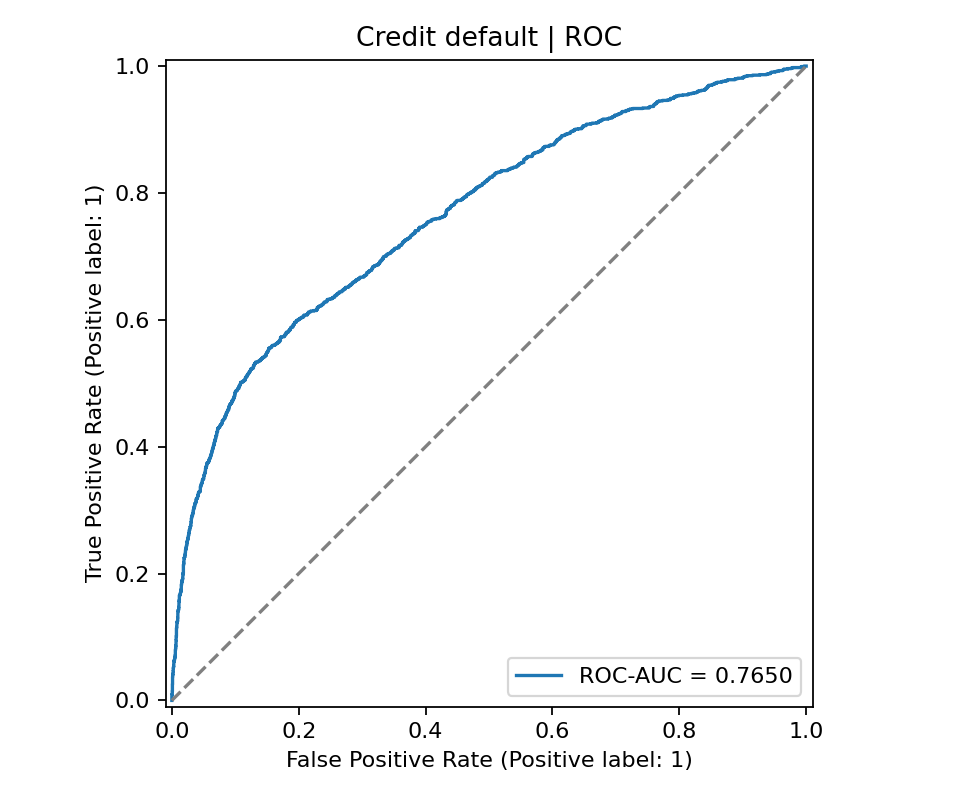

In [2]:
from IPython.display import display, Image
for image in sorted(OUT.glob("*.png")):
    display(Image(filename=str(image)))

## Sources and next steps

https://archive.ics.uci.edu/dataset/350/defaultofcreditcardclients

Review the README, rerun the tests and practice explaining the work before recording the required video. No LinkedIn post, GitHub publication or submission has been made by this notebook.